# Step 4 (version 2): spread and signals for the 15 pairs

**Goal.** Build the spread and the entry and exit signals for the **15 pairs of version 2** ([01_pairs.ipynb](01_pairs.ipynb)), on the **training period** only. They are the input of Step 5 (news agent) and Step 6 (simulation).

**Version 1 and version 2.** Version 1 has its own notebook ([segnali_coppie.ipynb](../Old%20files/src/04_segnali/segnali_coppie.ipynb), now in `Old files/`, in Italian). Here **the same rules and the same parameters** are applied to the version 2 pairs, without looking for new parameters: so the comparison between the two versions concerns only the pairs, not the signal.

**The group's choices applied** (version 2 decisions):
| Topic | Choice |
|---|---|
| Train/test split | The same for all pairs, in calendar dates: **train up to 16 September 2026, test from 17 September**. The test is not computed |
| Spread | Logarithm of the price ratio with **β = 1** (equal amounts on the two legs, no leverage) |
| Parameters | **Those of version 1**, the same for all: half-life 60 minutes, entry at \|z\| ≥ 2.0, exit at \|z\| ≤ 0, stop at 3.5, maximum time 90 minutes. No parameter search on version 2 |
| Times | No entry in the first 15 and in the last 30 minutes; everything closed at the end of the day |
| Filled bars | **No trade is opened if one of the two legs has a filled signal bar** (stale price); the discarded opportunities are counted |
| WDAY jump of 13 August | Left as it is (real move): no data excluded. What happens to the CRM-WDAY pair that day is reported |
| Dividends | Prices not adjusted, a limit to be stated |
| Costs | **Not considered** (the professor's indication): the profit is gross |
| Frequency | 1-minute bars |

**Where the rules are.** In the module [signals.py](signals.py); the reasons for each rule are in [segnale_mav.ipynb](../Old%20files/src/04_segnali/segnale_mav.ipynb) (in Italian) and are not repeated here. Before every entry: the signal is computed at the close of bar *t* and the order is executed at the open of bar *t+1*, to avoid using data that did not exist at the time of the decision (lookahead bias).

| Part | What it does | Why |
|---|---|---|
| 1 | Parameters | all the choices in one place |
| 2 | The 15 pairs: data and stationarity | description, not a filter |
| 3 | Checks: no lookahead, same results as version 1 on the pairs in common | the code must do what it declares |
| 4 | Signals and results pair by pair | how many trades and how much gross profit |
| 5 | Where the profit comes from | exit reason, time of day, filled bars, WDAY day |
| 6 | Saving the signals | input of Step 5 |
| 7 | Results (text for the report) | numbers generated from the data |

## 1. Parameters

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # project folder: makes src importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, coint

from src.config import PROCESSED, SIGNALS, TRAIN_END
from src.signals import list_pairs, load_pair, zscore, run_rules, OPEN_SKIP, CLOSE_SKIP, MAX_HOLD, STOP_EXTRA

OUT_SIGNALS = SIGNALS                                        # train signals of the 15 pairs, input of Step 5
V1_SIGNALS = PROCESSED / "signals_10pairs_train.csv"         # signals of the first selection: they exist only if its notebook (in Old files) was run

# --- Parameters of version 1, the same for all pairs (the group's choice: no new search) ---
HL, ENTRY, EXIT = 60, 2.0, 0.0      # EMA half-life (minutes), entry and exit thresholds in units of z

## 2. The 15 pairs: data and stationarity

For each pair: train and test days, share of minutes with a still leg (at least one of the two stocks without trades), oscillation of the spread within the day and between days, and two tests on the train spread (ADF and Engle-Granger cointegration, on 5-minute bars to reduce noise). **They are descriptions, not filters**: the list of pairs is already fixed.

In [2]:
pairs = list_pairs()
data = {p: load_pair(p) for p in pairs.pair}

rows = []
for p, d in data.items():
    tr = d.is_train
    sub = np.arange(len(d.S))[tr][::5]
    logA, logB = np.log(d.cA[sub]), np.log(d.cB[sub])
    s5 = d.S.iloc[sub]
    phi = np.polyfit(s5.shift(1).dropna(), s5.iloc[1:], 1)[0]
    daily = d.S[tr].groupby(d.ts[tr].normalize())
    rows.append(dict(pair=p, train_days=len(set(d.ts[tr].normalize())), test_days=len(set(d.ts[~tr].normalize())),
                     filled_A=d.filled_A[tr].mean(), filled_B=d.filled_B[tr].mean(), still_leg=d.stale[tr].mean(),
                     std_within_day_bps=daily.std().mean() * 1e4, std_between_days_bps=daily.mean().std() * 1e4,
                     adf_p=adfuller(s5, regression="c", autolag="AIC", result_object=False)[1], coint_p=coint(logA, logB, trend="c")[1],
                     half_life_days=(-np.log(2) / np.log(phi) / 78) if 0 < phi < 1 else np.inf))
info = pd.DataFrame(rows).set_index("pair")
info.style.format({"filled_A": "{:.1%}", "filled_B": "{:.1%}", "still_leg": "{:.1%}", "std_within_day_bps": "{:.0f}", "std_between_days_bps": "{:.0f}",
                   "adf_p": "{:.2f}", "coint_p": "{:.3f}", "half_life_days": "{:.1f}"})

,train_days,test_days,filled_A,filled_B,still_leg,std_within_day_bps,std_between_days_bps,adf_p,coint_p,half_life_days
pair,,,,,,,,,,
MA-V,64,32,9.5%,1.5%,10.6%,18,192,0.44,0.034,5.1
CSX-UNP,60,31,2.1%,41.4%,42.3%,25,192,0.32,0.152,3.5
PYPL-XYZ,64,32,1.0%,12.9%,13.6%,58,1030,0.49,0.193,9.1
HD-LOW,60,31,6.2%,33.5%,36.5%,24,199,0.08,0.561,3.5
DHR-TMO,60,31,27.1%,23.4%,41.2%,37,506,0.46,0.119,6.2
CRM-WDAY,64,32,2.3%,12.5%,14.3%,69,856,0.61,0.912,12.6
JPM-WFC,64,32,1.5%,2.4%,3.8%,30,254,0.31,0.582,5.5
NXPI-TXN,64,32,21.5%,7.2%,26.1%,48,584,0.47,0.303,9.2
ELV-UNH,64,32,35.2%,4.0%,37.0%,41,591,0.85,0.131,17.6


## 3. Checks

The signal code is the same as version 1: we must check that it does what it declares. Two checks:
1. **No lookahead.** The z-score of each bar does not change if the following bars are removed, for every pair.
2. **Same results as version 1 on the pairs in common.** The pairs MA-V, CSX-UNP, PYPL-XYZ, HD-LOW and KO-PEP are in both versions, with the same clean data and the same parameters: the trades must match those of `signals_10pairs_train.csv`.

In [3]:
for p, d in data.items():
    n_cut = len(d.S) // 2
    assert np.allclose(zscore(d.S.iloc[:n_cut], HL), zscore(d.S, HL)[:n_cut], equal_nan=True), f"{p}: the z-score uses future data"
print(f"OK: the z-score of each bar does not depend on the following bars ({len(data)} pairs)")

consistency = None
if V1_SIGNALS.exists():
    v1 = pd.read_csv(V1_SIGNALS, parse_dates=["t_signal", "t_entry", "t_exit"])
    common = sorted(set(v1.pair) & set(data))
    res = []
    for p in common:
        t_new, _ = run_rules(data[p], zscore(data[p].S, HL), ENTRY, EXIT)
        old = v1[v1.pair == p].sort_values("t_signal").reset_index(drop=True)
        same = len(t_new) == len(old) and (t_new.t_signal.values == old.t_signal.values).all() and np.allclose(t_new.gross_bps.values, old.gross_bps.values)
        res.append(dict(pair=p, trades_v2=len(t_new), trades_v1=len(old), identical=bool(same)))
    consistency = pd.DataFrame(res).set_index("pair")
    print("Check against version 1 on the pairs in common:"); print(consistency.to_string())
else:
    print(f"Check skipped: {V1_SIGNALS.name} is missing")

OK: the z-score of each bar does not depend on the following bars (15 pairs)
Check against version 1 on the pairs in common:
          trades_v2  trades_v1  identical
pair                                     
CSX-UNP          61         61       True
HD-LOW           65         65       True
KO-PEP           68         68       True
MA-V             75         75       True
PYPL-XYZ         60         60       True


## 4. Signals and results pair by pair

The rules with the version 1 parameters are applied to every pair, on the train only. The profit is **gross**, without costs. The standard error assumes independent trades; in reality trades of pairs of the same sector on the same day are linked, so the true uncertainty is a bit larger.

In [4]:
all_trades, rows = [], []
for p, d in data.items():
    tr, blocked = run_rules(d, zscore(d.S, HL), ENTRY, EXIT)
    all_trades.append(tr)
    rows.append(dict(pair=p, trade=len(tr), per_day=len(tr) / info.loc[p, "train_days"], gross_mean_bps=tr.gross_bps.mean() if len(tr) else np.nan,
                     std_error_bps=tr.gross_bps.std() / np.sqrt(len(tr)) if len(tr) > 1 else np.nan, positive=(tr.gross_bps > 0).mean() if len(tr) else np.nan,
                     exit_on_time=(tr.exit_reason == "time").mean() if len(tr) else np.nan, dropped_still_leg=blocked,
                     stale_exec_price=int(tr.exec_price_stale.sum()) if len(tr) else 0))
trades = pd.concat(all_trades, ignore_index=True)
per_pair = pd.DataFrame(rows).set_index("pair")

print(f"Parameters (the same for all, from version 1): half-life {HL} minutes, entry |z| >= {ENTRY}, exit |z| <= {EXIT}, stop |z| >= {ENTRY + STOP_EXTRA}, maximum time {MAX_HOLD} minutes")
print(f"TOTAL: {len(trades)} trades, mean gross {trades.gross_bps.mean():.1f} bps (standard error {trades.gross_bps.std() / np.sqrt(len(trades)):.1f}), median {trades.gross_bps.median():.1f}, positive {(trades.gross_bps > 0).mean():.0%}")
print(f"pairs with a positive mean profit: {(per_pair.gross_mean_bps > 0).sum()} of {len(per_pair)}; candidate bars dropped for a still leg: {per_pair.dropped_still_leg.sum()}")
per_pair.style.format({"per_day": "{:.2f}", "gross_mean_bps": "{:.1f}", "std_error_bps": "{:.1f}", "positive": "{:.0%}", "exit_on_time": "{:.0%}"})

Parameters (the same for all, from version 1): half-life 60 minutes, entry |z| >= 2.0, exit |z| <= 0.0, stop |z| >= 3.5, maximum time 90 minutes
TOTAL: 973 trades, mean gross 7.4 bps (standard error 2.0), median 10.8, positive 60%
pairs with a positive mean profit: 12 of 15; candidate bars dropped for a still leg: 233


,trade,per_day,gross_mean_bps,std_error_bps,positive,exit_on_time,dropped_still_leg,stale_exec_price
pair,,,,,,,,
MA-V,75,1.17,7.5,2.5,64%,36%,5,1
CSX-UNP,61,1.02,6.8,4.2,56%,41%,40,25
PYPL-XYZ,60,0.94,29.6,14.0,63%,47%,1,3
HD-LOW,65,1.08,4.4,4.1,68%,31%,35,12
DHR-TMO,62,1.03,6.6,6.5,58%,44%,36,21
CRM-WDAY,60,0.94,28.2,19.1,60%,48%,12,3
JPM-WFC,65,1.02,4.3,5.9,62%,38%,0,2
NXPI-TXN,68,1.06,-2.2,7.3,50%,44%,26,9
ELV-UNH,59,0.92,10.8,7.4,58%,58%,18,16


## 5. Where the profit comes from

Four descriptive checks, the same as version 1: how the trades exit, at what time they enter, how many are executed at a stale price, and what happens on the day of the WDAY jump (13 August), which we chose **not** to exclude. They change nothing in the signals: they help understand and write the report.

Exit reason:
             trade  mean gross (bps)
exit_reason                         
end_of_day      56               0.3
reversion      464              38.8
stop            31             -32.1
time           422             -23.2

Time slot of the entry (minutes from the open):
         trade  mean gross (bps)
slot                            
15-30      457              11.4
30-60      120              10.1
60-120     110               1.0
120-240    102              -3.8
240-390    184               5.9

entries in minutes 15-30: 457 trades of 973 (47%), 72% of the total gross profit, mean gross 11.4 bps
entries after 30 minutes: 516 trades, mean gross 3.9 bps (standard error 2.6)
executed at a stale price (bar t+1 filled): 129 trades of 973
trades with a signal of another pair in the same minute: 30%
without PYPL-XYZ (the pair with the highest mean profit): 913 trades, mean gross 6.0 bps (standard error 2.0)

CRM-WDAY on 13 August (WDAY jump): 5 trades, gross -2 bps (reversion),

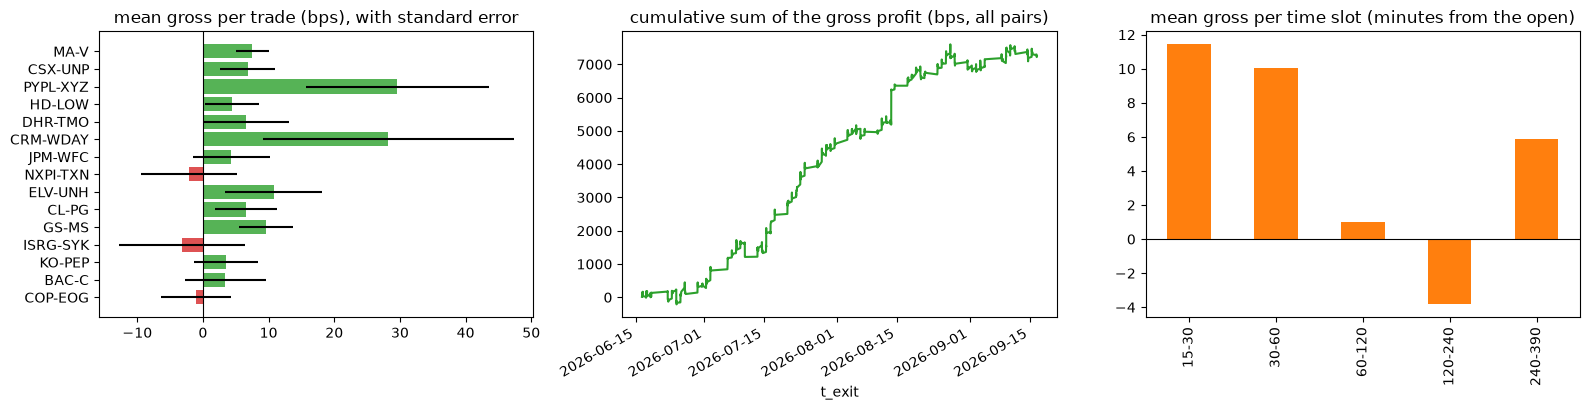

In [5]:
trades["slot"] = pd.cut(trades.minute_of_day, [0, 30, 60, 120, 240, 390], right=True, labels=["15-30", "30-60", "60-120", "120-240", "240-390"], include_lowest=True)
by_exit = trades.groupby("exit_reason").gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "mean gross (bps)"})
by_slot = trades.groupby("slot", observed=False).gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "mean gross (bps)"})
print("Exit reason:"); print(by_exit)
print("\nTime slot of the entry (minutes from the open):"); print(by_slot)

early = trades[trades.minute_of_day <= 30]; late = trades[trades.minute_of_day > 30]
early_share = early.gross_bps.sum() / trades.gross_bps.sum()
print(f"\nentries in minutes 15-30: {len(early)} trades of {len(trades)} ({len(early) / len(trades):.0%}), {early_share:.0%} of the total gross profit, mean gross {early.gross_bps.mean():.1f} bps")
print(f"entries after 30 minutes: {len(late)} trades, mean gross {late.gross_bps.mean():.1f} bps (standard error {late.gross_bps.std() / np.sqrt(len(late)):.1f})")
n_stale = int(trades.exec_price_stale.sum())
print(f"executed at a stale price (bar t+1 filled): {n_stale} trades of {len(trades)}")
overlap = trades.groupby("t_signal").pair.transform("size").gt(1).mean()
print(f"trades with a signal of another pair in the same minute: {overlap:.0%}")

best_pair = per_pair.gross_mean_bps.idxmax()
rest = trades[trades.pair != best_pair]
print(f"without {best_pair} (the pair with the highest mean profit): {len(rest)} trades, mean gross {rest.gross_bps.mean():.1f} bps (standard error {rest.gross_bps.std() / np.sqrt(len(rest)):.1f})")

wd = trades[(trades.pair == "CRM-WDAY") & (trades.t_signal.dt.date == pd.Timestamp("2026-08-13").date())]
print(f"\nCRM-WDAY on 13 August (WDAY jump): {len(wd)} trades, gross " + (", ".join(f"{g:.0f} bps ({r})" for g, r in zip(wd.gross_bps, wd.exit_reason)) if len(wd) else "no trade"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].barh(per_pair.index, per_pair.gross_mean_bps, xerr=per_pair.std_error_bps, color=np.where(per_pair.gross_mean_bps > 0, "tab:green", "tab:red"), alpha=0.8)
ax[0].axvline(0, color="k", lw=0.8); ax[0].set_title("mean gross per trade (bps), with standard error"); ax[0].invert_yaxis()
trades.sort_values("t_exit").set_index("t_exit").gross_bps.cumsum().plot(ax=ax[1], color="tab:green"); ax[1].set_title("cumulative sum of the gross profit (bps, all pairs)")
trades.groupby("slot", observed=False).gross_bps.mean().plot.bar(ax=ax[2], color="tab:orange"); ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_title("mean gross per time slot (minutes from the open)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Saving the train signals

Table of the signals of all pairs: input of Step 5. Same columns as version 1 (`pair`, `ticker_A` and `ticker_B`, times of the signal, the entry and the exit in New York time, `direction`, `z_signal`, `most_moved_leg`, returns of the last 30 minutes, prices, `exit_reason`, `gross_bps` gross without costs, `exec_price_stale`, parameters). File **separate** from the version 1 one; folder ignored by git.

In [6]:
out = trades.sort_values(["t_signal", "pair"]).reset_index(drop=True)
out["signal_id"] = out.index
out["ema"] = "continuous"
out["hl_min"], out["entry_z"], out["exit_z"], out["stop_z"] = HL, ENTRY, EXIT, ENTRY + STOP_EXTRA
cols = ["signal_id", "pair", "ticker_A", "ticker_B", "t_signal", "t_entry", "t_exit", "direction", "z_signal", "most_moved_leg", "ret_A_30m", "ret_B_30m",
        "price_A_in", "price_B_in", "price_A_out", "price_B_out", "exit_reason", "gross_bps", "minutes_in_trade", "exec_price_stale", "ema", "hl_min", "entry_z", "exit_z", "stop_z"]
assert out.t_exit.max() < pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), "the signal file contains test days"
OUT_SIGNALS.parent.mkdir(parents=True, exist_ok=True)
out[cols].to_csv(OUT_SIGNALS, index=False)
print(f"saved {len(out)} signals of {out.pair.nunique()} pairs in {OUT_SIGNALS.name} (last day: {out.t_exit.max().date()}, train cut: {TRAIN_END})")
out[cols].head()

saved 973 signals of 15 pairs in signals_15pairs_v2_train.csv (last day: 2026-09-16, train cut: 2026-09-16)


,signal_id,pair,ticker_A,ticker_B,t_signal,t_entry,t_exit,direction,z_signal,most_moved_leg,...,price_B_out,exit_reason,gross_bps,minutes_in_trade,exec_price_stale,ema,hl_min,entry_z,exit_z,stop_z
0,0,COP-EOG,COP,EOG,2026-06-16 10:31:00,2026-06-16 10:32:00,2026-06-16 10:55:00,long COP / short EOG,-2.194212,EOG,...,130.780,reversion,13.788510,23.0,False,continuous,60,2.0,0.0,3.5
1,1,KO-PEP,KO,PEP,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:19:00,short KO / long PEP,2.035824,PEP,...,145.650,reversion,31.056741,14.0,False,continuous,60,2.0,0.0,3.5
2,2,MA-V,MA,V,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:23:00,short MA / long V,2.073157,MA,...,330.275,reversion,25.179270,18.0,False,continuous,60,2.0,0.0,3.5
3,3,COP-EOG,COP,EOG,2026-06-16 11:31:00,2026-06-16 11:32:00,2026-06-16 12:20:00,long COP / short EOG,-2.469532,EOG,...,131.460,reversion,19.471550,48.0,False,continuous,60,2.0,0.0,3.5
4,4,GS-MS,GS,MS,2026-06-16 11:45:00,2026-06-16 11:46:00,2026-06-16 12:12:00,long GS / short MS,-2.178510,GS,...,221.070,reversion,38.294415,26.0,False,continuous,60,2.0,0.0,3.5


## 7. Results (text for the report)

The next cell generates the text from the results of the notebook: if data or parameters change, the numbers update by themselves.

In [7]:
from IPython.display import Markdown, display

v1_line = ""
if V1_SIGNALS.exists():
    v1g = v1.gross_bps
    v1_line = f"- **Comparison with version 1** (same parameters): {len(v1)} trades, {v1g.mean():.1f} bps gross on average (standard error {v1g.std() / np.sqrt(len(v1)):.1f}); version 2: {len(trades)} trades, {trades.gross_bps.mean():.1f} bps."
cons_line = ""
if consistency is not None:
    cons_line = f"- **Consistency check**: on the {len(consistency)} pairs in common with version 1 the trades are " + ("identical" if consistency.identical.all() else "NOT identical: " + ", ".join(consistency.index[~consistency.identical])) + "."
se = trades.gross_bps.std() / np.sqrt(len(trades))
pos = per_pair.gross_mean_bps.sort_values()
top = per_pair.sort_values("gross_mean_bps", ascending=False).head(3)
bot = per_pair.sort_values("gross_mean_bps").head(3)
exit_txt = ", ".join(f"{k} {int(r['trade'])} trades ({r['mean gross (bps)']:+.0f} bps)" for k, r in by_exit.iterrows())
stale_pairs = per_pair.still_leg if "still_leg" in per_pair else info.still_leg
still = info.still_leg.sort_values(ascending=False).head(4)
lines = [
    "### What we did",
    f"We built the spread of each of the {len(pairs)} version 2 pairs as the difference of the log prices (equal amounts on the two legs, β = 1) and computed the z-score with exponential mean and standard deviation (half-life {HL} minutes, continuous over the whole series). The trade enters at the next bar if |z| ≥ {ENTRY}, and exits on reversion (|z| ≤ {EXIT}), stop (|z| ≥ {ENTRY + STOP_EXTRA}), maximum time ({MAX_HOLD} minutes) or end of the day. Parameters **equal to those of version 1**, no new search. Training period only (16 June - 16 September 2026), costs excluded.",
    "",
    "### Why",
    "The signal is the same as version 1 so that the two lists of pairs can be compared without the rule changing too; the test (from 17 September) stays unused and no new parameters are searched, so as not to fit them to the data. No trade is opened if a leg has a filled bar, because otherwise the spread widens only because one stock is still. Costs are not considered by the professor's indication.",
    "",
    "### Results on the train",
    f"- **Total**: {len(trades)} trades ({len(trades) / len(pairs) / info.train_days.mean():.2f} per day per pair), mean **gross** profit {trades.gross_bps.mean():.1f} bps (standard error {se:.1f}), median {trades.gross_bps.median():.1f}, {(trades.gross_bps > 0).mean():.0%} positive; {int((per_pair.gross_mean_bps > 0).sum())} pairs of {len(per_pair)} with a positive mean profit.",
    "- **Best pairs**: " + ", ".join(f"{p} {r.gross_mean_bps:.1f} bps ({int(r.trade)} trades, error {r.std_error_bps:.1f})" for p, r in top.iterrows()) + ". **Worst**: " + ", ".join(f"{p} {r.gross_mean_bps:.1f} bps ({int(r.trade)} trades)" for p, r in bot.iterrows()) + ".",
    f"- **Without {best_pair}** (the pair with the highest mean profit): {len(rest)} trades, {rest.gross_bps.mean():.1f} bps (error {rest.gross_bps.std() / np.sqrt(len(rest)):.1f}).",
    f"- **How the trades exit**: {exit_txt}.",
    f"- **Time of day**: the entries of minutes 15-30 are {len(early)} trades ({len(early) / len(trades):.0%}) and produce {early_share:.0%} of the gross profit (mean gross {early.gross_bps.mean():.1f} bps); after 30 minutes {len(late)} trades make {late.gross_bps.mean():.1f} bps (error {late.gross_bps.std() / np.sqrt(len(late)):.1f}).",
    f"- **Filled bars**: {n_stale} trades ({n_stale / len(trades):.0%}) are executed at the next bar when it is filled (not a real trade price) and {int(per_pair.dropped_still_leg.sum())} opportunities are dropped for a still leg. Pairs with a still leg most often: " + ", ".join(f"{p} {v:.0%}" for p, v in still.items()) + ".",
    f"- **Stationarity on the train**: Engle-Granger below 0.05 for {int((info.coint_p < 0.05).sum())} pairs of {len(info)}; ADF below 0.05 for {int((info.adf_p < 0.05).sum())} of {len(info)}. Half-life of the spread from {info.half_life_days.min():.1f} to {info.half_life_days.replace(np.inf, np.nan).max():.1f} days.",
    "- **Day of the WDAY jump (13 August)**: " + (f"CRM-WDAY has {len(wd)} trades that day, with gross profit " + ", ".join(f"{g:.0f} bps" for g in wd.gross_bps) + f". The largest trade ({wd.gross_bps.max():.0f} bps) is worth {wd.gross_bps.max() / trades.gross_bps.sum():.0%} of the total gross profit of the {len(pairs)} pairs; without it the mean would drop to {(trades.gross_bps.sum() - wd.gross_bps.max()) / (len(trades) - 1):.1f} bps and that of CRM-WDAY to {(trades[trades.pair == 'CRM-WDAY'].gross_bps.sum() - wd.gross_bps.max()) / (len(trades[trades.pair == 'CRM-WDAY']) - 1):.1f} bps. By the group's choice the day is not excluded: the figure is reported here because it weighs a lot on the result." if len(wd) else "CRM-WDAY has no trade that day."),
    f"- **Overlapping signals**: {overlap:.0%} of the trades have a signal of another pair in the same minute: the trades are not independent and the standard errors are underestimated.",
    v1_line, cons_line,
    "",
    "### What it means",
    "- The profit is gross (no cost, by the professor's indication) and must be read together with the standard error: pairs with few trades and large errors cannot be told apart from zero.",
    "- If most of the profit comes from the first 30 minutes, it is above all the reversion of the overnight gap, not a move within the day: to be stated in the report.",
    "- The test (from 17 September) was not computed.",
]
display(Markdown("\n".join(l for l in lines if l is not None)))

### What we did
We built the spread of each of the 15 version 2 pairs as the difference of the log prices (equal amounts on the two legs, β = 1) and computed the z-score with exponential mean and standard deviation (half-life 60 minutes, continuous over the whole series). The trade enters at the next bar if |z| ≥ 2.0, and exits on reversion (|z| ≤ 0.0), stop (|z| ≥ 3.5), maximum time (90 minutes) or end of the day. Parameters **equal to those of version 1**, no new search. Training period only (16 June - 16 September 2026), costs excluded.

### Why
The signal is the same as version 1 so that the two lists of pairs can be compared without the rule changing too; the test (from 17 September) stays unused and no new parameters are searched, so as not to fit them to the data. No trade is opened if a leg has a filled bar, because otherwise the spread widens only because one stock is still. Costs are not considered by the professor's indication.

### Results on the train
- **Total**: 973 trades (1.04 per day per pair), mean **gross** profit 7.4 bps (standard error 2.0), median 10.8, 60% positive; 12 pairs of 15 with a positive mean profit.
- **Best pairs**: PYPL-XYZ 29.6 bps (60 trades, error 14.0), CRM-WDAY 28.2 bps (60 trades, error 19.1), ELV-UNH 10.8 bps (59 trades, error 7.4). **Worst**: ISRG-SYK -3.2 bps (63 trades), NXPI-TXN -2.2 bps (68 trades), COP-EOG -1.0 bps (61 trades).
- **Without PYPL-XYZ** (the pair with the highest mean profit): 913 trades, 6.0 bps (error 2.0).
- **How the trades exit**: end_of_day 56 trades (+0 bps), reversion 464 trades (+39 bps), stop 31 trades (-32 bps), time 422 trades (-23 bps).
- **Time of day**: the entries of minutes 15-30 are 457 trades (47%) and produce 72% of the gross profit (mean gross 11.4 bps); after 30 minutes 516 trades make 3.9 bps (error 2.6).
- **Filled bars**: 129 trades (13%) are executed at the next bar when it is filled (not a real trade price) and 233 opportunities are dropped for a still leg. Pairs with a still leg most often: CSX-UNP 42%, DHR-TMO 41%, ELV-UNH 37%, HD-LOW 37%.
- **Stationarity on the train**: Engle-Granger below 0.05 for 1 pairs of 15; ADF below 0.05 for 0 of 15. Half-life of the spread from 2.9 to 17.6 days.
- **Day of the WDAY jump (13 August)**: CRM-WDAY has 5 trades that day, with gross profit -2 bps, 7 bps, 72 bps, -42 bps, 985 bps. The largest trade (985 bps) is worth 14% of the total gross profit of the 15 pairs; without it the mean would drop to 6.4 bps and that of CRM-WDAY to 12.0 bps. By the group's choice the day is not excluded: the figure is reported here because it weighs a lot on the result.
- **Overlapping signals**: 30% of the trades have a signal of another pair in the same minute: the trades are not independent and the standard errors are underestimated.
- **Comparison with version 1** (same parameters): 624 trades, 6.8 bps gross on average (standard error 2.1); version 2: 973 trades, 7.4 bps.
- **Consistency check**: on the 5 pairs in common with version 1 the trades are identical.

### What it means
- The profit is gross (no cost, by the professor's indication) and must be read together with the standard error: pairs with few trades and large errors cannot be told apart from zero.
- If most of the profit comes from the first 30 minutes, it is above all the reversion of the overnight gap, not a move within the day: to be stated in the report.
- The test (from 17 September) was not computed.